In [1]:
!pip -q install medmnist scikit-learn seaborn pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 1.3 MB/s eta 0:00:00


In [22]:
import os
import copy
import random
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

import medmnist
from medmnist import INFO

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("MedMNIST:", medmnist.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
MedMNIST: 3.0.2
Device: cpu


In [23]:

DATA_FLAG = "bloodmnist"

# Short labels for plots and visualizations only
short_names = [
    "Basophil",
    "Eosinophil",
    "Erythroblast",
    "Immature granulocyte",
    "Lymphocyte",
    "Monocyte",
    "Neutrophil",
    "Platelet"
]

info = INFO[DATA_FLAG]
DataClass = getattr(medmnist, info["python_class"])

# Load the official splits
raw_train_dataset = DataClass(
    split="train",
    download=True,
    transform=transforms.ToTensor()
)

raw_val_dataset = DataClass(
    split="val",
    download=True,
    transform=transforms.ToTensor()
)

raw_test_dataset = DataClass(
    split="test",
    download=True,
    transform=transforms.ToTensor()
)

# class names from MedMNIST
class_names = [
    info["label"][str(i)]
    for i in range(len(info["label"]))
]

NUM_CLASSES = len(class_names)

# Ensure display labels match the dataset classes
assert len(short_names) == NUM_CLASSES, (
    "The number of short labels must match the number of classes."
)

print("Original class names:", class_names)
print("Short display names:", short_names)
print("Number of classes:", NUM_CLASSES)
print("Training images:", len(raw_train_dataset))
print("Validation images:", len(raw_val_dataset))
print("Test images:", len(raw_test_dataset))


Original class names: ['basophil', 'eosinophil', 'erythroblast', 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Short display names: ['Basophil', 'Eosinophil', 'Erythroblast', 'Immature granulocyte', 'Lymphocyte', 'Monocyte', 'Neutrophil', 'Platelet']
Number of classes: 8
Training images: 11959
Validation images: 1712
Test images: 3421


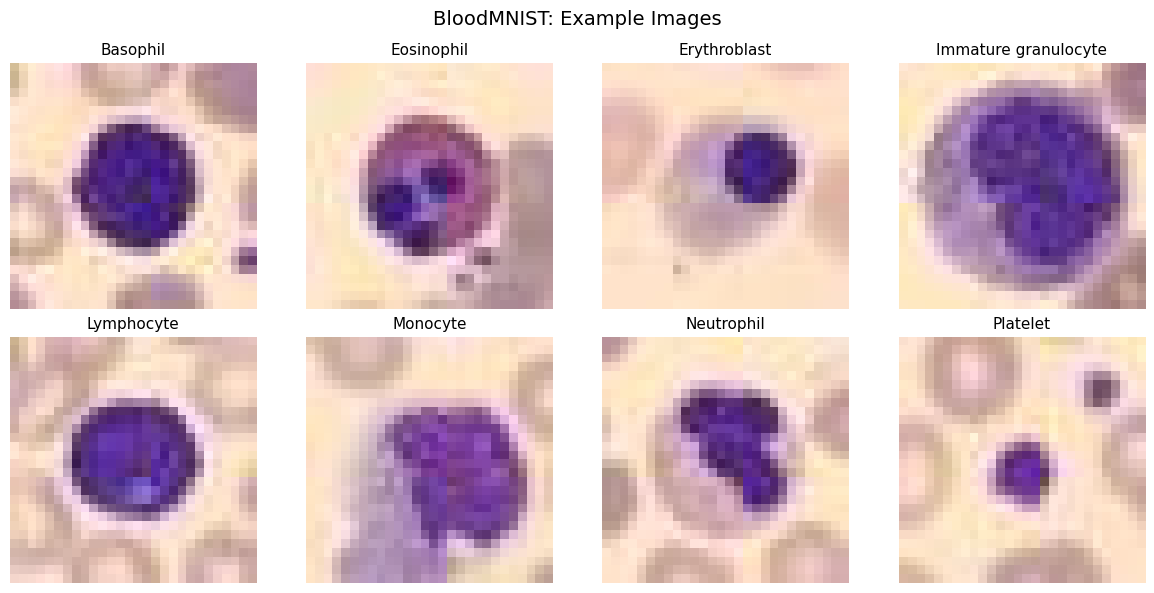

In [24]:
# Display representative images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for class_id, ax in enumerate(axes.flat):
    indices = np.where(
        raw_train_dataset.labels.reshape(-1) == class_id
    )[0]

    idx = indices[0]
    image, label = raw_train_dataset[idx]

    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(short_names[class_id], fontsize=11)
    ax.axis("off")

plt.suptitle("BloodMNIST: Example Images", fontsize=14)
plt.tight_layout()
plt.show()

,Class,Train,Validation,Test
0,Basophil,852,122,244
1,Eosinophil,2181,312,624
2,Erythroblast,1085,155,311
3,Immature granulocyte,2026,290,579
4,Lymphocyte,849,122,243
5,Monocyte,993,143,284
6,Neutrophil,2330,333,666
7,Platelet,1643,235,470


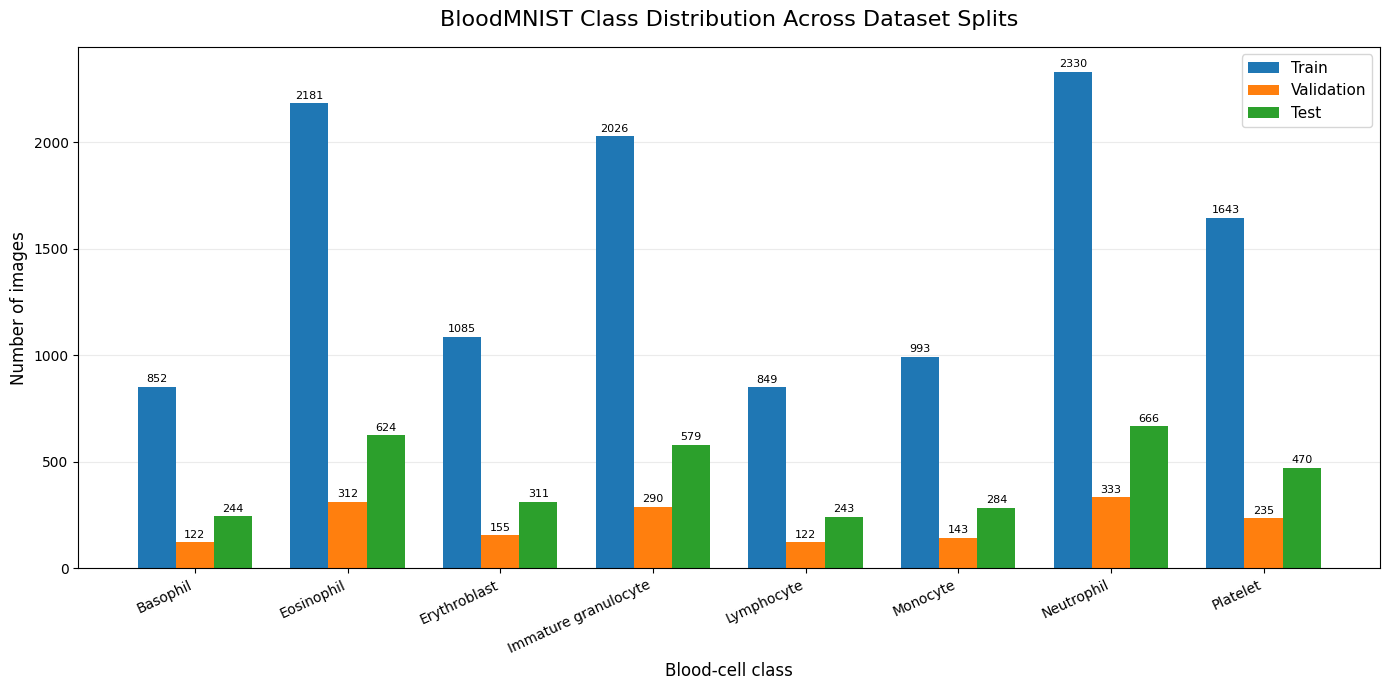

In [25]:

train_labels = raw_train_dataset.labels.reshape(-1).astype(int)
val_labels = raw_val_dataset.labels.reshape(-1).astype(int)
test_labels = raw_test_dataset.labels.reshape(-1).astype(int)

counts = pd.DataFrame({
    "Class": short_names,
    "Train": np.bincount(train_labels, minlength=NUM_CLASSES),
    "Validation": np.bincount(val_labels, minlength=NUM_CLASSES),
    "Test": np.bincount(test_labels, minlength=NUM_CLASSES)
})

display(counts)

x = np.arange(NUM_CLASSES)
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))

bars1 = ax.bar(x - width, counts["Train"], width, label="Train")
bars2 = ax.bar(x, counts["Validation"], width, label="Validation")
bars3 = ax.bar(x + width, counts["Test"], width, label="Test")

ax.set_title("BloodMNIST Class Distribution Across Dataset Splits",
             fontsize=16, pad=15)
ax.set_xlabel("Blood-cell class", fontsize=12)
ax.set_ylabel("Number of images", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(short_names, rotation=25, ha="right", fontsize=10)

ax.bar_label(bars1, padding=2, fontsize=8)
ax.bar_label(bars2, padding=2, fontsize=8)
ax.bar_label(bars3, padding=2, fontsize=8)

ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("/content/bloodmnist_class_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [26]:
stats_loader = DataLoader(
    raw_train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2
)

channel_sum = torch.zeros(3)
channel_sq_sum = torch.zeros(3)
num_pixels = 0

for images, _ in stats_loader:
    batch_pixels = images.shape[0] * images.shape[2] * images.shape[3]

    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sq_sum += (images ** 2).sum(dim=(0, 2, 3))
    num_pixels += batch_pixels

channel_mean = channel_sum / num_pixels
channel_var = channel_sq_sum / num_pixels - channel_mean ** 2
channel_std = torch.sqrt(channel_var.clamp(min=1e-8))

mean = channel_mean.tolist()
std = channel_std.tolist()

print("Training-set mean:", mean)
print("Training-set std:", std)

Training-set mean: [0.7943478226661682, 0.6596590876579285, 0.6961925625801086]
Training-set std: [0.2156306356191635, 0.24160327017307281, 0.11788870394229889]


In [27]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = DataClass(
    split="train", download=True, transform=train_transform
)

val_dataset = DataClass(
    split="val", download=True, transform=eval_transform
)

test_dataset = DataClass(
    split="test", download=True, transform=eval_transform
)

BATCH_SIZE = 128

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([128, 3, 28, 28])
Label batch shape: torch.Size([128, 1])


In [28]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=0.30)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(x)
        return self.classifier(x)


model = SmallCNN(num_classes=NUM_CLASSES).to(device)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"Trainable parameters: {num_params:,}")

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (dropout): Dropout(p=0.3, inplace=False)
  

In [29]:
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 30
PATIENCE = 7

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

CHECKPOINT_PATH = "/content/best_bloodmnist_cnn.pth"

In [30]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    all_targets = []
    all_preds = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.view(-1).long().to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)

        all_targets.extend(labels.detach().cpu().numpy())
        all_preds.extend(predictions.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_targets, all_preds)

    return avg_loss, accuracy

In [31]:
history = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "class_names": class_names,
            "mean": mean,
            "std": std,
            "seed": SEED
        }, CHECKPOINT_PATH)

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

elapsed_minutes = (time.time() - start_time) / 60

history_df = pd.DataFrame(history)
history_df.to_csv("/content/training_history.csv", index=False)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Training time: {elapsed_minutes:.2f} minutes")
print("Checkpoint saved:", CHECKPOINT_PATH)

Epoch 01/30 | Train Loss: 0.8495 | Train Acc: 0.7136 | Val Loss: 0.5512 | Val Acc: 0.8020 | LR: 1.00e-03
Epoch 02/30 | Train Loss: 0.4559 | Train Acc: 0.8450 | Val Loss: 0.3707 | Val Acc: 0.8750 | LR: 1.00e-03
Epoch 03/30 | Train Loss: 0.3712 | Train Acc: 0.8680 | Val Loss: 0.3623 | Val Acc: 0.8814 | LR: 1.00e-03
Epoch 04/30 | Train Loss: 0.3385 | Train Acc: 0.8798 | Val Loss: 0.3448 | Val Acc: 0.8657 | LR: 1.00e-03
Epoch 05/30 | Train Loss: 0.3099 | Train Acc: 0.8933 | Val Loss: 0.2672 | Val Acc: 0.9001 | LR: 1.00e-03
Epoch 06/30 | Train Loss: 0.2846 | Train Acc: 0.8986 | Val Loss: 0.4592 | Val Acc: 0.8417 | LR: 1.00e-03
Epoch 07/30 | Train Loss: 0.2713 | Train Acc: 0.9029 | Val Loss: 0.5134 | Val Acc: 0.8230 | LR: 1.00e-03
Epoch 08/30 | Train Loss: 0.2626 | Train Acc: 0.9055 | Val Loss: 0.3033 | Val Acc: 0.8902 | LR: 5.00e-04
Epoch 09/30 | Train Loss: 0.2225 | Train Acc: 0.9242 | Val Loss: 0.1960 | Val Acc: 0.9282 | LR: 5.00e-04
Epoch 10/30 | Train Loss: 0.2172 | Train Acc: 0.9228 | 

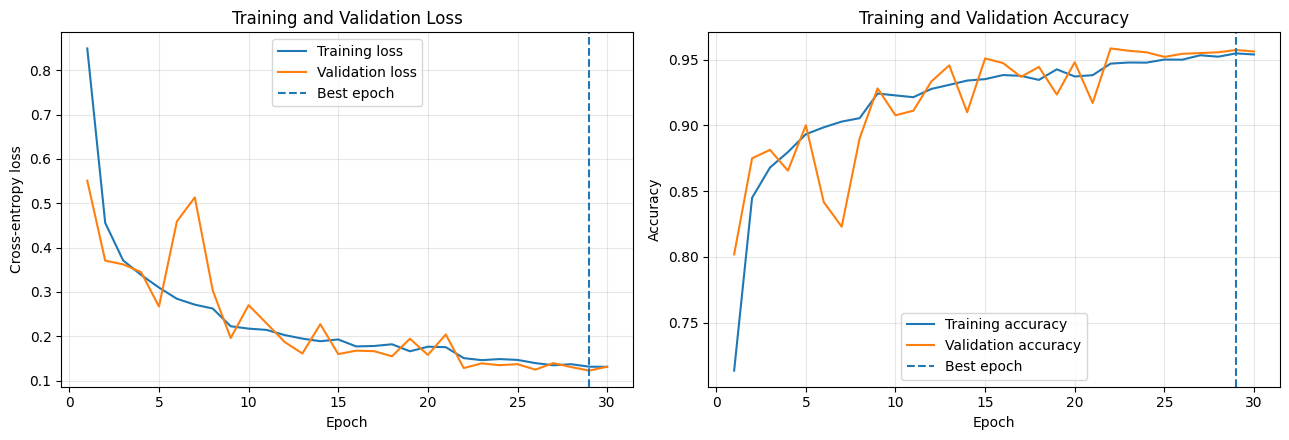

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    history_df["epoch"], history_df["train_loss"],
    label="Training loss"
)
axes[0].plot(
    history_df["epoch"], history_df["val_loss"],
    label="Validation loss"
)
axes[0].axvline(
    best_epoch, linestyle="--", label="Best epoch"
)
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_df["epoch"], history_df["train_accuracy"],
    label="Training accuracy"
)
axes[1].plot(
    history_df["epoch"], history_df["val_accuracy"],
    label="Validation accuracy"
)
axes[1].axvline(
    best_epoch, linestyle="--", label="Best epoch"
)
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/content/training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [33]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_targets = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.view(-1).long().to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        all_targets.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

y_true = np.asarray(all_targets)
y_pred = np.asarray(all_predictions)
y_prob = np.asarray(all_probabilities)

test_accuracy = accuracy_score(y_true, y_pred)

precision_macro, recall_macro, f1_macro, _ = (
    precision_recall_fscore_support(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )
)

precision_weighted, recall_weighted, f1_weighted, _ = (
    precision_recall_fscore_support(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )
)

try:
    macro_auc = roc_auc_score(
        y_true,
        y_prob,
        multi_class="ovr",
        average="macro",
        labels=np.arange(NUM_CLASSES)
    )
except ValueError:
    macro_auc = float("nan")

results = {
    "Best epoch": checkpoint["epoch"],
    "Test accuracy": test_accuracy,
    "Macro precision": precision_macro,
    "Macro recall": recall_macro,
    "Macro F1": f1_macro,
    "Weighted F1": f1_weighted,
    "Macro ROC-AUC (OVR)": macro_auc
}

results_df = pd.DataFrame(
    results.items(), columns=["Metric", "Value"]
)

display(results_df.round(4))

results_df.to_csv("/content/test_metrics.csv", index=False)

print("\nPer-class classification report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=short_names,
    digits=4,
    zero_division=0
))

,Metric,Value
0,Best epoch,29.0000
1,Test accuracy,0.9468
2,Macro precision,0.9481
3,Macro recall,0.9359
4,Macro F1,0.9415
5,Weighted F1,0.9466
6,Macro ROC-AUC (OVR),0.9971



Per-class classification report:

                      precision    recall  f1-score   support

            Basophil     0.9483    0.9016    0.9244       244
          Eosinophil     0.9920    0.9888    0.9904       624
        Erythroblast     0.9708    0.9614    0.9661       311
Immature granulocyte     0.8569    0.8895    0.8729       579
          Lymphocyte     0.9496    0.9300    0.9397       243
            Monocyte     0.9219    0.8310    0.8741       284
          Neutrophil     0.9452    0.9850    0.9647       666
            Platelet     1.0000    1.0000    1.0000       470

            accuracy                         0.9468      3421
           macro avg     0.9481    0.9359    0.9415      3421
        weighted avg     0.9472    0.9468    0.9466      3421



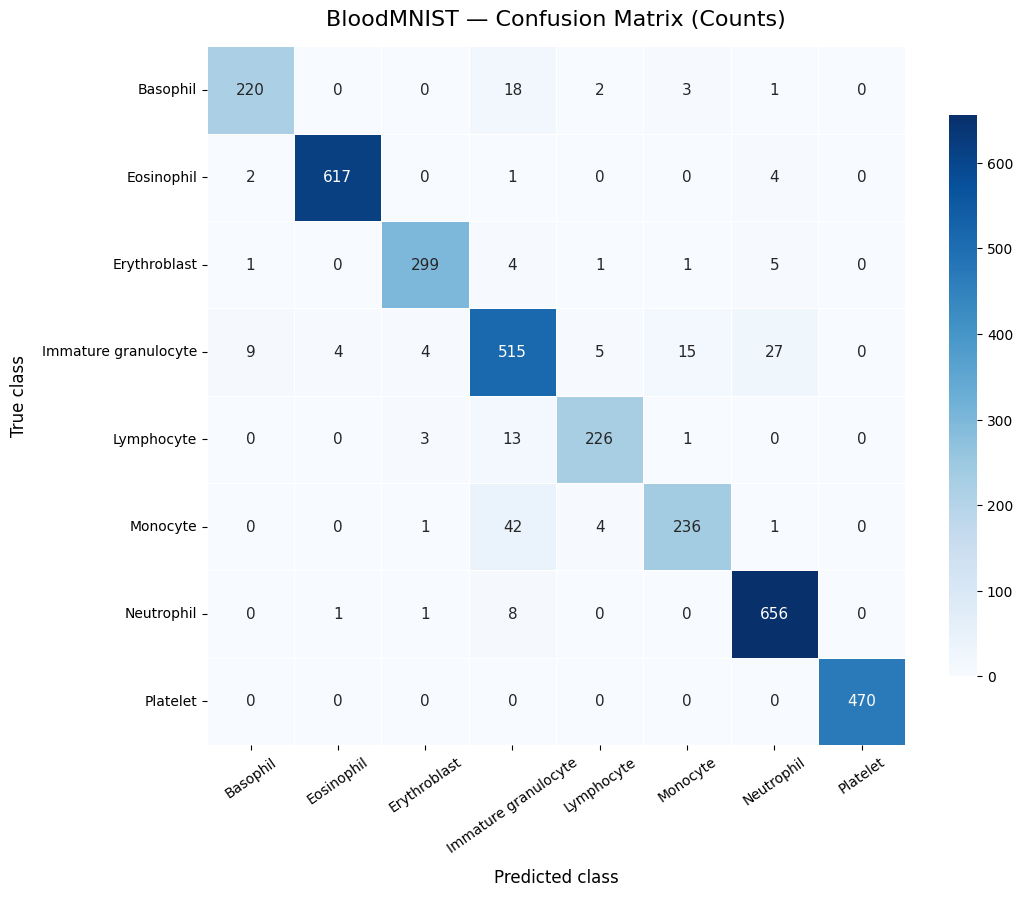

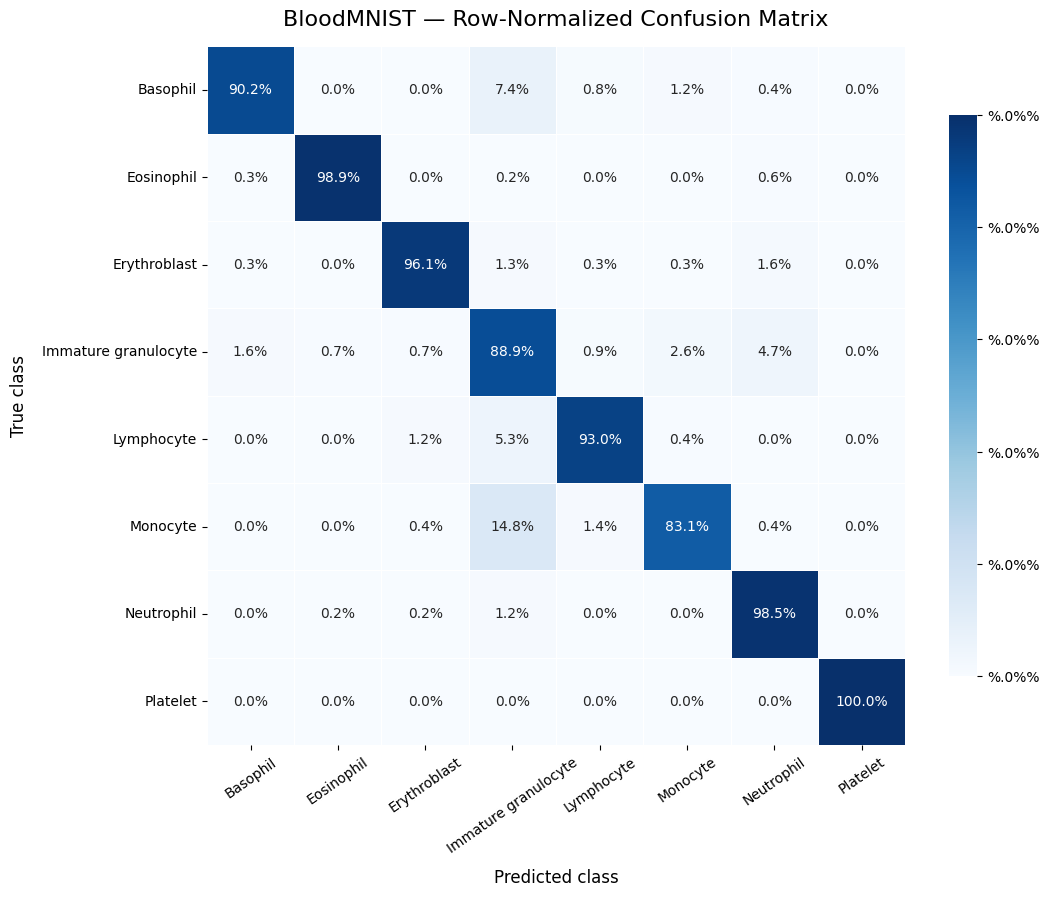

In [34]:

cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(NUM_CLASSES)
)

# Row-normalized matrix: each row sums to 1.
cm_normalized = cm.astype(float) / np.maximum(
    cm.sum(axis=1, keepdims=True), 1
)

# Figure 1: Confusion matrix counts

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=short_names,
    yticklabels=short_names,
    linewidths=0.5,
    linecolor="white",
    square=True,
    annot_kws={"size": 11},
    cbar_kws={"shrink": 0.8},
    ax=ax
)

ax.set_title("BloodMNIST — Confusion Matrix (Counts)", fontsize=16, pad=15)
ax.set_xlabel("Predicted class", fontsize=12, labelpad=10)
ax.set_ylabel("True class", fontsize=12, labelpad=10)
ax.tick_params(axis="x", labelrotation=35, labelsize=10)
ax.tick_params(axis="y", labelrotation=0, labelsize=10)

plt.tight_layout()
plt.savefig(
    "/content/confusion_matrix_counts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Figure 2: Row-normalized confusion matrix

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=short_names,
    yticklabels=short_names,
    linewidths=0.5,
    linecolor="white",
    square=True,
    annot_kws={"size": 10},
    cbar_kws={"shrink": 0.8, "format": "%.0%%"},
    ax=ax
)

ax.set_title(
    "BloodMNIST — Row-Normalized Confusion Matrix",
    fontsize=16,
    pad=15
)
ax.set_xlabel("Predicted class", fontsize=12, labelpad=10)
ax.set_ylabel("True class", fontsize=12, labelpad=10)
ax.tick_params(axis="x", labelrotation=35, labelsize=10)
ax.tick_params(axis="y", labelrotation=0, labelsize=10)

plt.tight_layout()
plt.savefig(
    "/content/confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


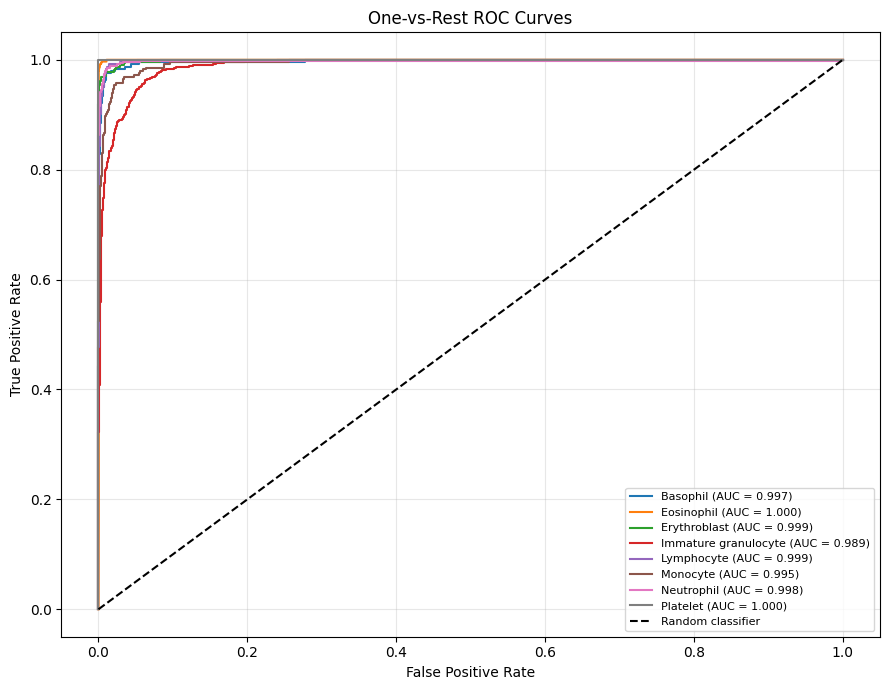

In [35]:
y_true_binary = label_binarize(
    y_true,
    classes=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(9, 7))

for i, name in enumerate(short_names):
    fpr, tpr, _ = roc_curve(
        y_true_binary[:, i],
        y_prob[:, i]
    )

    class_auc = auc(fpr, tpr)

    ax.plot(
        fpr, tpr,
        label=f"{name} (AUC = {class_auc:.3f})"
    )

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("One-vs-Rest ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/content/roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

Misclassified images: 182
Test images: 3421


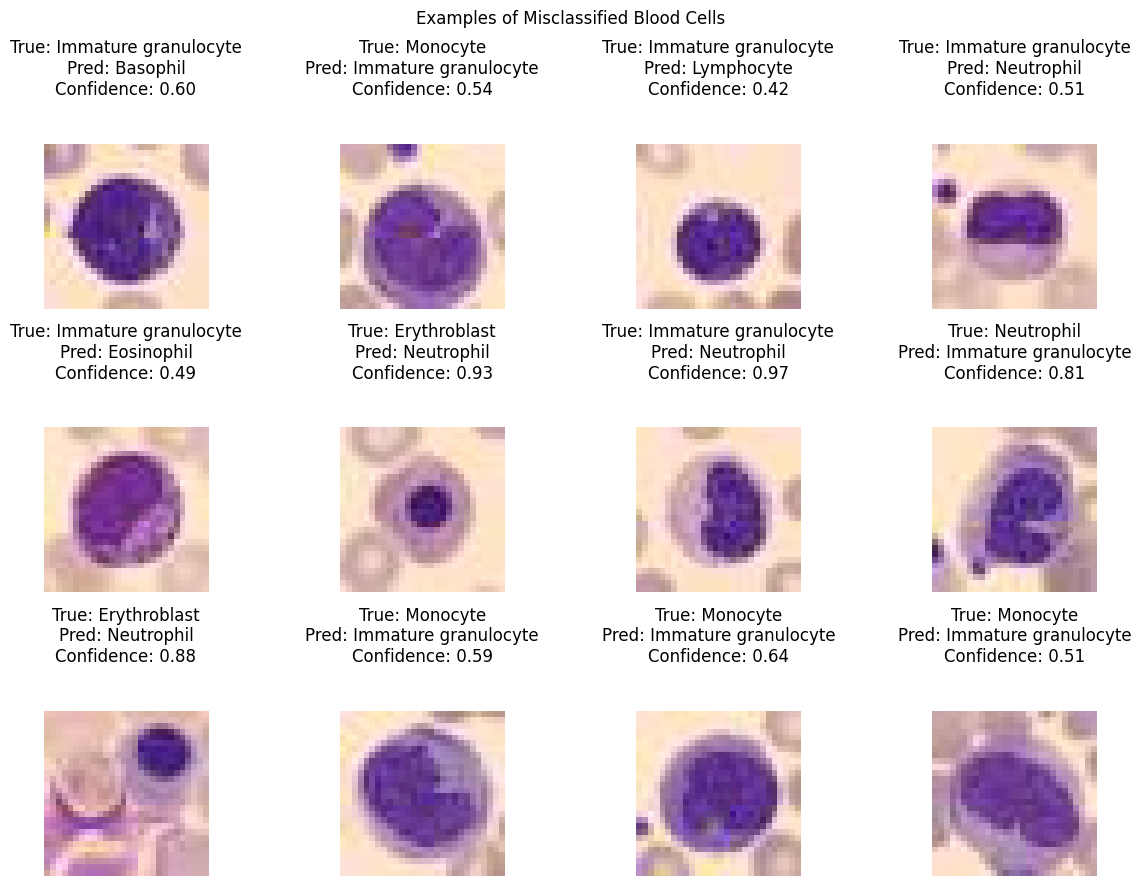

In [36]:
wrong_indices = np.where(y_true != y_pred)[0]

print("Misclassified images:", len(wrong_indices))
print("Test images:", len(y_true))

if len(wrong_indices) > 0:
    rng = np.random.default_rng(SEED)
    selected = rng.choice(
        wrong_indices,
        size=min(12, len(wrong_indices)),
        replace=False
    )

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))

    for ax, idx in zip(axes.flat, selected):
        image, label = test_dataset[int(idx)]

        # Reverse normalization for display.
        image = image.cpu() * torch.tensor(std).view(3, 1, 1)
        image = image + torch.tensor(mean).view(3, 1, 1)
        image = image.clamp(0, 1)

        ax.imshow(image.permute(1, 2, 0).numpy())
        ax.set_title(
            f"True: {short_names[y_true[idx]]}\n"
            f"Pred: {short_names[y_pred[idx]]}\n"
            f"Confidence: {y_prob[idx].max():.2f}\n\n"
        )
        ax.axis("off")

    for ax in axes.flat[len(selected):]:
        ax.axis("off")

    plt.suptitle("Examples of Misclassified Blood Cells")
    plt.tight_layout()
    plt.savefig("/content/misclassified_examples.png",
                dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No misclassified test examples.")

In [37]:
report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=short_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    "/content/classification_report.csv"
)

pd.DataFrame(
    cm,
    index=short_names,
    columns=short_names
).to_csv("/content/confusion_matrix.csv")

predictions_df = pd.DataFrame({
    "true_label": y_true,
    "true_class": [short_names[i] for i in y_true],
    "predicted_label": y_pred,
    "predicted_class": [short_names[i] for i in y_pred],
    "confidence": y_prob.max(axis=1)
})

for i, name in enumerate(short_names):
    predictions_df[f"prob_{name}"] = y_prob[:, i]

predictions_df.to_csv("/content/test_predictions.csv", index=False)

config = {
    "dataset": "BloodMNIST",
    "dataset_version": medmnist.__version__,
    "model": "SmallCNN",
    "input_shape": [3, 28, 28],
    "num_classes": NUM_CLASSES,
    "class_names": class_names,
    "display_names": short_names,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "best_epoch": best_epoch,
    "normalization_mean": mean,
    "normalization_std": std,
    "augmentation": ["RandomHorizontalFlip", "RandomRotation(10)"]
}

with open("/content/experiment_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Experiment artifacts saved in /content/")

Experiment artifacts saved in /content/


In [38]:
from google.colab import files

files.download("/content/best_bloodmnist_cnn.pth")
files.download("/content/training_history.csv")
files.download("/content/test_metrics.csv")
files.download("/content/classification_report.csv")
files.download("/content/test_predictions.csv")
files.download("/content/experiment_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>